# 01 EDA: trips, POIs, and the target

All logic lives in `src/biketrips`; this notebook only calls it. Part 1 iterates on a reproducible 10% sample (hash of trip id, seed 42). Part 2 confirms the key numbers on all 44.6M trips (five files, 30 days) with DuckDB.

## EDA findings

- **Data is clean at the row level, dirty at the GPS level.** No null, unparseable or duplicate fields in 9,980,998 trips. 0.15% are dropped: 11,539 have a (0, 0) GPS placeholder, 2,025 start far outside Shenzhen (clusters in other provinces, e.g. 126.4E 43.9N), 318 start in Shenzhen but end outside, 1,406 have zero or over-4h durations.
- **Coordinates mix two datums.** Trips, metro and bus stops are in GCJ-02 (AMap's offset system); POIs, the boundary and the population raster are WGS84. The offset is about 550 m, more than one H3 res-8 edge. Trips and stops are shifted to WGS84 with an offset measured from POIs that carry both.
- **Effective window is 8 days**, 2021-07-31 to 2021-08-07. Jul 28 to 30 have under 100 trips in total. Clear commute peaks at 8:00 and 18:00.
- **Zeros are the norm, not noise.** On the full 3,272-cell grid, 42% of cells have no trip end. Dropping them would hide the hardest part of the problem. 769 zero cells have POIs, and 82% of cells east of 114.25E are zero (they hold 0.8% of trips), which looks like an operator coverage gap (supply), not a lack of demand.
- **Counts are heavily overdispersed**: mean 3,046 vs variance 6.0e7 (ratio about 20,000). A Poisson GLM can still rank cells, but its implied uncertainty is far too narrow.
- **Demand is spatially smooth.** Moran's I is 0.70 on counts and 0.87 on log1p counts; a cell's log count correlates 0.95 with its neighbour mean. A random split leaks this, so we evaluate with spatial blocks and add a spatial kNN baseline.
- **POIs matter broadly.** Most categories have Spearman 0.6 to 0.82 with trip ends; Pass Facilities and Transportation Service lead. The three used by Baseline LR (Sports & Recreation, Transportation, Medical) span 0.72 to 0.82, so using all categories adds breadth more than a missing star feature.
- **1% is too little.** With a 1% sample, 613 of 1,898 cells that do have trips look empty, and the median per-cell error after scaling is 27% (8% at 10%). We use all trips.


In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from biketrips import config, data, features, plots, quality

warnings.filterwarnings("ignore", module="openpyxl")
pd.set_option("display.width", 140)
cfg = config.load_config()
con = data.connect()

## Part 1: preliminary 10% sample

### Schema, dtypes, null rates

In [2]:
data.clean_trips(con, cfg, frac=cfg["eda"]["sample_fraction"])
quality.null_rates(con, "trips_flagged")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,column_name,column_type,count,null_percentage,min,max,approx_unique
0,trip_id,VARCHAR,4462339,0.00,6235d85fd9eb0867d7831fab,6236ad7cd9eb0867d72c043f,4546765
1,user_id,VARCHAR,4462339,0.00,0000085c570e5e6de7f904**********,fffffdf3fa918ad75633a2**********,1749596
2,start_time,TIMESTAMP,4462339,0.00,2019-11-17 12:38:57,2021-08-31 01:32:41,1849538
3,end_time,TIMESTAMP,4462339,0.00,2019-11-17 12:41:08,2021-08-31 01:35:28,1815103
4,start_lat,DOUBLE,4462339,0.00,0.0,47.6609125,2402210
5,start_lng,DOUBLE,4462339,0.00,0.0,132.5358773,2622400
6,end_lat,DOUBLE,4462339,0.00,-28.49456369,40.824753,3885340
7,end_lng,DOUBLE,4462339,0.00,-28.34166717,120.64064,3792628
8,dup_rank,BIGINT,4462339,0.00,1,1,1
9,trip_rank,BIGINT,4462339,0.00,1,2,2


### Coordinate validity

Share of trips charged to each cleaning rule (first rule that fails), then where the bad coordinates land.

In [3]:
quality.drop_summary(con)

,reason,n,pct
0,kept,4451571,99.7587
1,zero_coords,4627,0.1037
2,outside_window,3911,0.0876
3,duplicate_trip,811,0.0182
4,zero_duration,690,0.0155
5,start_out_of_bounds,628,0.0141
6,end_out_of_bounds,86,0.0019
7,extreme_duration,15,0.0003


In [4]:
quality.invalid_points(con).head(12)

,drop_reason,side,lng,lat,n
0,zero_coords,start,0.0,0.0,3173
1,zero_coords,end,0.0,0.0,1454
2,start_out_of_bounds,start,116.2,23.0,97
3,start_out_of_bounds,start,126.4,43.9,62
4,start_out_of_bounds,start,113.6,24.5,54
5,start_out_of_bounds,start,110.5,40.6,51
6,start_out_of_bounds,start,106.5,29.6,50
7,start_out_of_bounds,start,132.5,47.7,38
8,start_out_of_bounds,start,114.5,25.6,28
9,start_out_of_bounds,start,132.0,47.2,20


### Trip duration

0.000        0.0
0.001        9.0
0.010       41.0
0.250      326.0
0.500      515.0
0.750      844.0
0.990     5606.0
0.999    10410.0
1.000    28701.0
Name: duration_s, dtype: float64


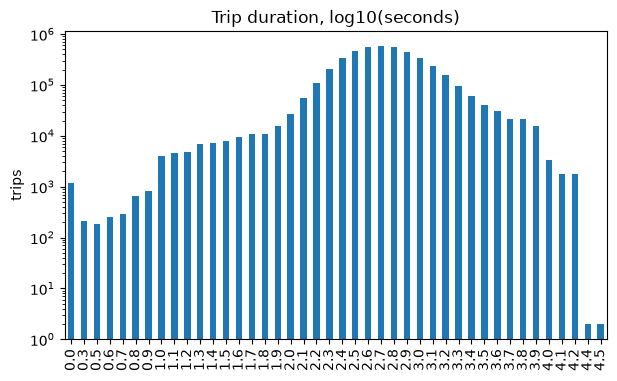

In [5]:
print(quality.durations(con))
plots.bar(quality.duration_hist(con).set_index("log10_s")["n"], title="Trip duration, log10(seconds)", ylabel="trips", log=True);

### Temporal pattern

day         weekday  
2021-07-31  Saturday      89408
2021-08-01  Sunday       133591
2021-08-02  Monday       146189
2021-08-03  Tuesday      154730
2021-08-04  Wednesday    137342
2021-08-05  Thursday     116471
2021-08-06  Friday       138663
2021-08-07  Saturday     141162
2021-08-08  Sunday       116631
2021-08-09  Monday       132202
2021-08-10  Tuesday      150878
2021-08-11  Wednesday    151961
2021-08-12  Thursday     148216
2021-08-13  Friday       168492
2021-08-14  Saturday     133590
2021-08-15  Sunday       145375
2021-08-16  Monday       167239
2021-08-17  Tuesday      170970
2021-08-18  Wednesday    168504
2021-08-19  Thursday     170976
2021-08-20  Friday       174216
2021-08-21  Saturday     152407
2021-08-22  Sunday       139867
2021-08-23  Monday       168939
2021-08-24  Tuesday      172603
2021-08-25  Wednesday    173760
2021-08-26  Thursday     179585
2021-08-27  Friday       155032
2021-08-28  Saturday     162074
2021-08-29  Sunday        90498
Name: n, dtype: in

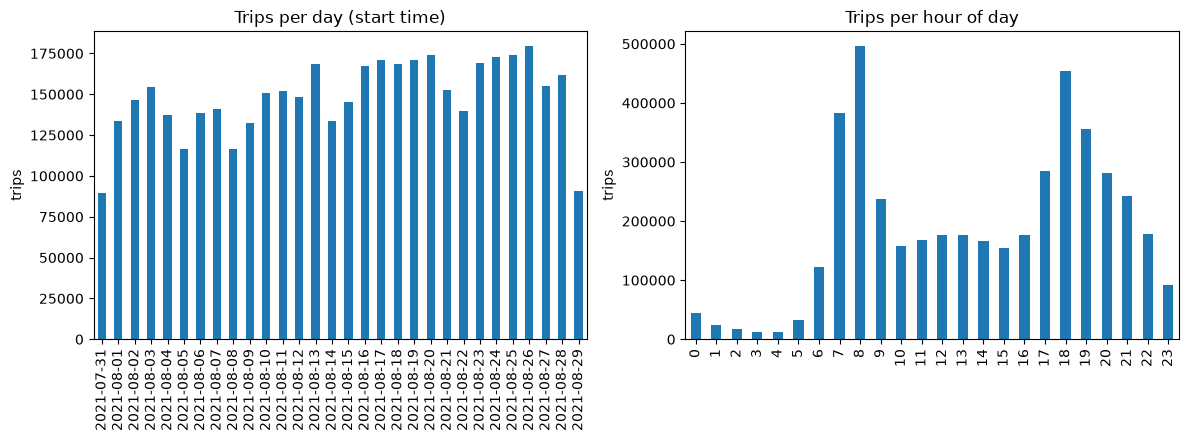

In [6]:
tmp = quality.temporal(con)
plots.temporal(tmp);
tmp.groupby(["day", "weekday"])["n"].sum()

## Part 2: full dataset

Re-run cleaning on all trips with logging, build the full H3 grid over the boundary, and count trip ends per cell. Cells with no trip end get 0.

In [7]:
log = quality.DropLog(cfg["data"]["interim_dir"] / "eda_drop_log.csv")
data.clean_trips(con, cfg, frac=1.0, log=log)
quality.drop_summary(con)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,reason,n,pct
0,kept,44444490,99.6000
1,duplicate_trip,77020,0.1726
2,zero_coords,47825,0.1072
3,outside_window,39204,0.0879
4,zero_duration,7346,0.0165
5,start_out_of_bounds,6001,0.0134
6,end_out_of_bounds,981,0.0022
7,extreme_duration,134,0.0003


In [8]:
res = cfg["features"]["h3_res"]
grid = features.full_grid(data.load_boundary(cfg), res, cfg["features"]["boundary_buffer_deg"])
weeks = cfg["features"]["weeks"]
target = features.trip_target(con, grid, log, cfg["cleaning"]["window"][0], weeks)
print(len(grid), "cells")
quality.overdispersion(target["trips"])

3272 cells


{'mean': np.float64(13582.489914425429),
 'variance': np.float64(1210685249.0549104),
 'var_to_mean': np.float64(89135.73701748817),
 'zero_share': np.float64(0.33312958435207823)}

### Per-cell trip-end counts

Variance far above the mean means a plain Poisson model is overdispersed: its point predictions can still be fine, but its implied uncertainty is far too narrow.

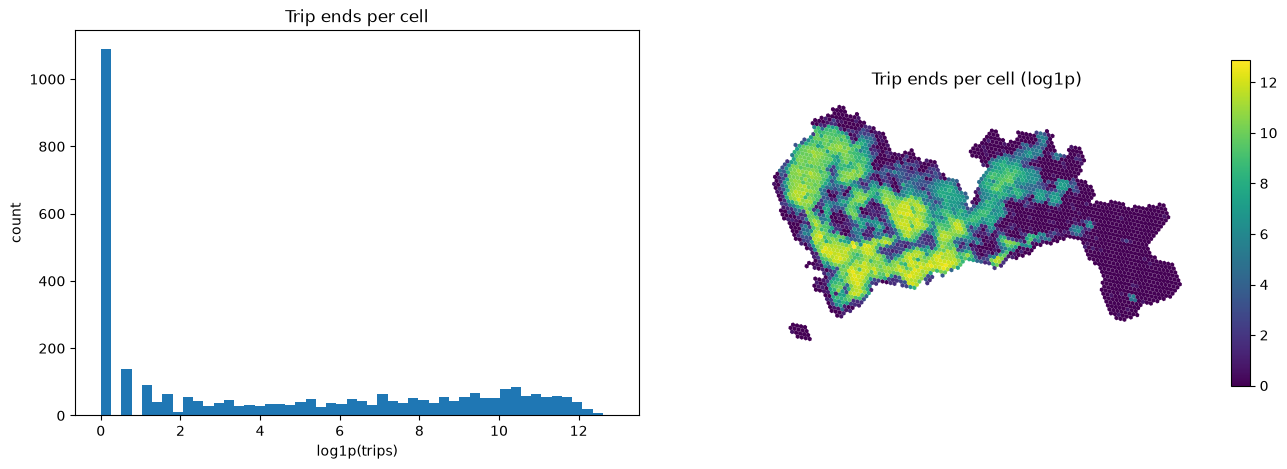

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
plots.hist(np.log1p(target["trips"]), ax[0], title="Trip ends per cell", xlabel="log1p(trips)")
plots.cell_map(target, "trips", ax[1], title="Trip ends per cell", log=True);

### POI categories

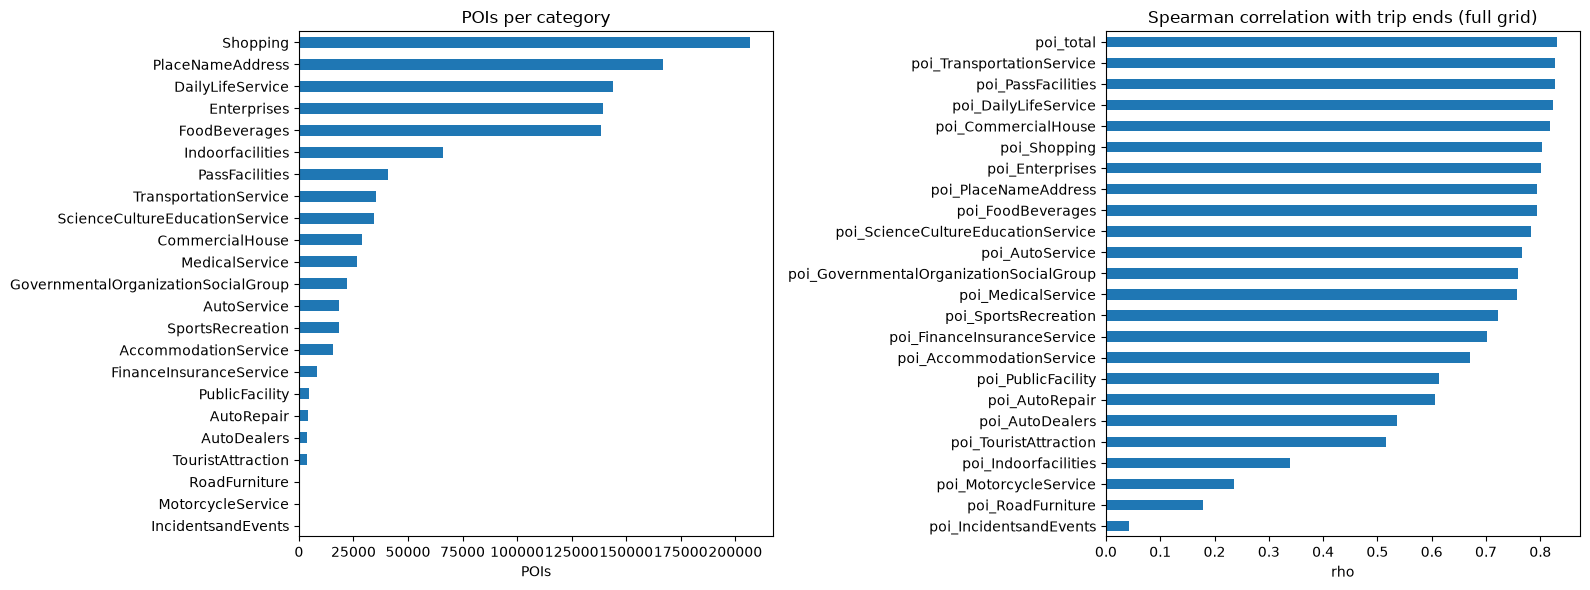

In [10]:
pois = data.load_pois(cfg, log)
metro, bus = data.load_transit(cfg, log)
poi = features.poi_counts(pois, grid, res, log)
cells = target.merge(poi, on="h3")
poi_cols = [c for c in poi.columns if c.startswith("poi_") and c != "poi_total"]
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plots.bar(pois["category"].value_counts().sort_values(), ax[0], "POIs per category", "POIs", horizontal=True)
plots.bar(quality.correlations(cells, poi_cols + ["poi_total"]).sort_values(), ax[1],
          "Spearman correlation with trip ends (full grid)", "rho", horizontal=True)
plt.tight_layout()

### Spatial autocorrelation of the target

Moran's I with H3 k-ring 1 weights. Strong positive autocorrelation means a random split puts near-copies of each test cell in the training set.

Moran's I, trips: 0.706
Moran's I, log1p(trips): 0.877
corr(log1p cell, neighbour mean): 0.954


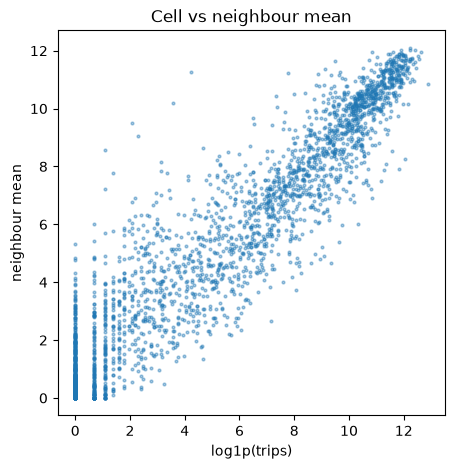

In [11]:
adj = features.neighbors(grid["h3"].tolist())
nbr = features.neighbor_mean(adj, np.log1p(cells["trips"]))
print("Moran's I, trips:", round(features.morans_i(adj, cells["trips"]), 3))
print("Moran's I, log1p(trips):", round(features.morans_i(adj, np.log1p(cells["trips"])), 3))
print("corr(log1p cell, neighbour mean):", round(pd.Series(np.log1p(cells["trips"])).corr(pd.Series(nbr)), 3))
plots.scatter(np.log1p(cells["trips"]), nbr, title="Cell vs neighbour mean", xlabel="log1p(trips)", ylabel="neighbour mean");

### Do zero cells stay zero?

Trip ends per cell for each of the 4 full weeks. If empty cells were just quiet, many would get trips in another week. If they stay empty, the operator likely does not serve them.

In [12]:
print(target["weeks_served"].value_counts().sort_index().rename("cells by weeks with any trip"))
quality.zero_persistence(target, weeks)

weeks_served
0    1111
1     201
2     120
3     114
4    1726
Name: cells by weeks with any trip, dtype: int64


,zero_share,still_zero_if_zero_in_w1,spearman_vs_w1
trips_w1,0.422372,1.000000,1.000000
trips_w2,0.419621,0.922576,0.974245
trips_w3,0.412592,0.909551,0.968315
trips_w4,0.396088,0.871925,0.960599


### Sample vs full: how noisy is a small sample?

Fractions give about 100k trips (the original 1% sample), 1M, 10M (one trip file) and all trips. Counts from nested hash samples are scaled by 1/fraction and compared with the full count. `false_zero_cells` are cells that look empty in the sample but have real trips.

In [13]:
noise = quality.sample_noise(con, cells, cfg["eda"]["noise_fractions"], cfg["seed"])
noise

,fraction,trips,cells_seen,false_zero_cells,median_rel_error,p90_rel_error,spearman_vs_full
0,0.00225,99343,1336,846,0.434893,1.0,0.899663
1,0.02250,997646,1651,531,0.113825,1.0,0.950473
2,0.22500,9999761,1951,231,0.030898,1.0,0.981670
3,1.00000,44441907,2182,0,0.000000,0.0,1.000000


## Drop and fill log

The same log, extended with population and transit steps, is written to `results/data_quality.md` by `scripts/build_features.py`. This notebook only displays it and does not save.

In [14]:
log.df

,stage,step,action,rows,of,reason
0,trips,raw rows,info,44623001,44623001,100% of 2*_1000w.csv
1,trips,missing_id,drop,0,44623001,no trip id
2,trips,duplicate_id,drop,0,44623001,"repeated trip id, first kept"
3,trips,duplicate_trip,drop,77020,44623001,"same user, start time and start point under an..."
4,trips,bad_timestamp,drop,0,44545981,null or unparseable timestamp
5,trips,outside_window,drop,39204,44545981,start time outside the study window
6,trips,end_before_start,drop,0,44506777,end time before start
7,trips,zero_duration,drop,7346,44506777,duration under min_duration_s
8,trips,extreme_duration,drop,134,44499431,duration over max_duration_s
9,trips,missing_coords,drop,0,44499297,null coordinate
